# Training a neural network with particle swarm optimisation
### F21BC Biologically Inspired Computation: coursework walk-through

This notebook goes through the implementation one piece at a time:

1. the banknote authentication data and the train/test split
2. the feedforward network (`src/mlp`)
3. the coupling between the network and PSO (`src/adapter`)
4. PSO itself, following Algorithm 39 of *Essentials of Metaheuristics* (`src/pso`)
5. training, convergence and test results
6. a few small experiments (10 runs each, so the notebook stays quick)
7. PSO choosing the activation function

Everything in `src/` is written with NumPy only. The full experimental study (30 runs per
setting, significance tests, figures) is run by the scripts in the companion repository
`bio-inspired-coursework` and written up in `report/`.

## 0. Setup

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import matplotlib.pyplot as plt

from src.data.dataset import load_banknote, stratified_train_test_split, Standardiser, FEATURE_NAMES
from src.evaluation.metrics import classification_report
from src.mlp.builder import MLPBuilder
from src.adapter.mlp_fitness_adapter import MLPFitnessAdapter
from src.adapter.activation_search_adapter import ActivationSearchAdapter
from src.pso.population import Population
from src.pso.informant_strategy import make_informant_strategy

BLUE, ORANGE, AQUA = "#257de0", "#f47230", "#00b894"
plt.rcParams.update({"figure.figsize": (7, 3.2), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e7e7e7", "lines.linewidth": 2})

## 1. Data

The UCI banknote authentication data has 1372 samples, four features computed from images of
banknotes, and a 0/1 class label. We keep 30% of each class for testing (a stratified split) and
standardise the inputs using the mean and standard deviation of the training set only.

In [2]:
X, y = load_banknote("../data/data_banknote_authentication.txt")
print("samples:", X.shape[0], " features:", FEATURE_NAMES, " class counts:", np.bincount(y))

X_train, X_test, y_train, y_test = stratified_train_test_split(X, y, test_fraction=0.3, seed=42)
scaler = Standardiser().fit(X_train)
X_train, X_test = scaler.transform(X_train), scaler.transform(X_test)
y_train_column = y_train.reshape(-1, 1).astype(float)

print("training:", X_train.shape, " test:", X_test.shape)
print("share of class 1 in training / test: %.3f / %.3f" % (y_train.mean(), y_test.mean()))

samples: 1372  features: ['variance', 'skewness', 'curtosis', 'entropy']  class counts: [762 610]
training: (960, 4)  test: (412, 4)
share of class 1 in training / test: 0.445 / 0.444


## 2. The network

`MLPBuilder` turns a short configuration into a `Network`. The number of layers, the size of each
layer and the activation of each layer are all set here. The input size comes from the data, and a
binary task gets one logistic output unit.

In [3]:
def build_network(hidden=(8,), activations=("tanh",)):
    builder = MLPBuilder(rng=np.random.default_rng(0))
    builder.set_dataset(X_train, y_train_column)
    builder.set_configuration({
        "hidden_layers": list(hidden),
        "activations": list(activations),
        "task": "binary_classification",
    })
    return builder.build()

network, loss = build_network()
print("network:", network.describe())
print("weights and biases (length of a PSO particle):", network.count_parameters())

# The evaluation code can be tried before any training, on a network with random weights:
random_labels = (network.predict(X_test).ravel() >= 0.5).astype(int)
print("random network, test accuracy: %.3f" % classification_report(y_test, random_labels)["accuracy"])

network: 4-8(tanh)-1(logistic)
weights and biases (length of a PSO particle): 49
random network, test accuracy: 0.235


## 3. Coupling PSO and the network

PSO only needs an object with an `evaluate(position)` method. `MLPFitnessAdapter` provides it:

1. write the position vector into the network (`Network.set_parameters`),
2. classify the **training** set,
3. return the fraction classified correctly as the particle's fitness.

In [4]:
fitness = MLPFitnessAdapter(network, loss, X_train, y_train_column, fitness="accuracy")

particle_position = np.random.default_rng(1).uniform(-1, 1, size=fitness.dimension)
print("a random particle has fitness (training accuracy): %.3f" % fitness.evaluate(particle_position))
print("the vector is now inside the network:", np.allclose(network.get_parameters(), particle_position))

a random particle has fitness (training accuracy): 0.652
the vector is now inside the network: True


## 4. PSO (Algorithm 39)

`Population.optimise()` follows Algorithm 39 line by line (the comments in `src/pso/population.py`
and `src/pso/particle.py` give the line numbers). The symbols are the book's:

| symbol | meaning | argument |
|---|---|---|
| α | proportion of velocity retained | `inertia_weight` |
| β | pull towards the particle's own best | `cognitive_coefficient` |
| γ | pull towards its informants' best | `social_coefficient` |
| δ | pull towards the global best | `global_coefficient` |
| ε | jump size | `step_size` |

Below is the final configuration from the report: 25 particles, 40 iterations (1000 evaluations),
α = 0.4, β = γ = 1, δ = 0, three random informants per particle.

In [5]:
def train(seed=0, hidden=(8,), activations=("tanh",), alpha=0.4, beta=1.0, gamma=1.0, delta=0.0,
          swarm_size=25, iterations=40, informants=3, strategy="random", search_activations=False):
    network, loss = build_network(hidden, activations)
    adapter_class = ActivationSearchAdapter if search_activations else MLPFitnessAdapter
    fitness = adapter_class(network, loss, X_train, y_train_column, fitness="accuracy")
    population = Population(
        fitness_function=fitness, dimension=fitness.dimension,
        num_particles=swarm_size, num_iterations=iterations,
        inertia_weight=alpha, cognitive_coefficient=beta, social_coefficient=gamma,
        global_coefficient=delta, step_size=1.0,
        num_informants=min(informants, swarm_size - 1),
        informant_strategy=make_informant_strategy(strategy),
        track_diversity=True, seed=seed,
    )
    best_position, best_fitness = population.optimise()
    fitness.install(best_position)                       # best particle -> network
    test = classification_report(y_test, fitness.to_labels(network.predict(X_test)))
    return {"network": network, "population": population, "train_accuracy": best_fitness, **test}

result = train(seed=0)
print("fitness evaluations used:", result["population"].evaluations)
print("training accuracy: %.4f" % result["train_accuracy"])

fitness evaluations used: 1000
training accuracy: 1.0000


## 5. Test results and convergence

In [6]:
print("test accuracy  %.4f" % result["accuracy"])
print("test precision %.4f" % result["precision"])
print("test recall    %.4f" % result["recall"])
print("test F1        %.4f" % result["f1"])
print("confusion counts: TP %d  TN %d  FP %d  FN %d" % (result["tp"], result["tn"], result["fp"], result["fn"]))

test accuracy  1.0000
test precision 1.0000
test recall    1.0000
test F1        1.0000
confusion counts: TP 183  TN 229  FP 0  FN 0


The same network trained with the usual literature coefficients (α = 0.72, β = γ = 1.5) converges
more slowly. The right-hand plot shows why: its swarm keeps spreading out instead of contracting.

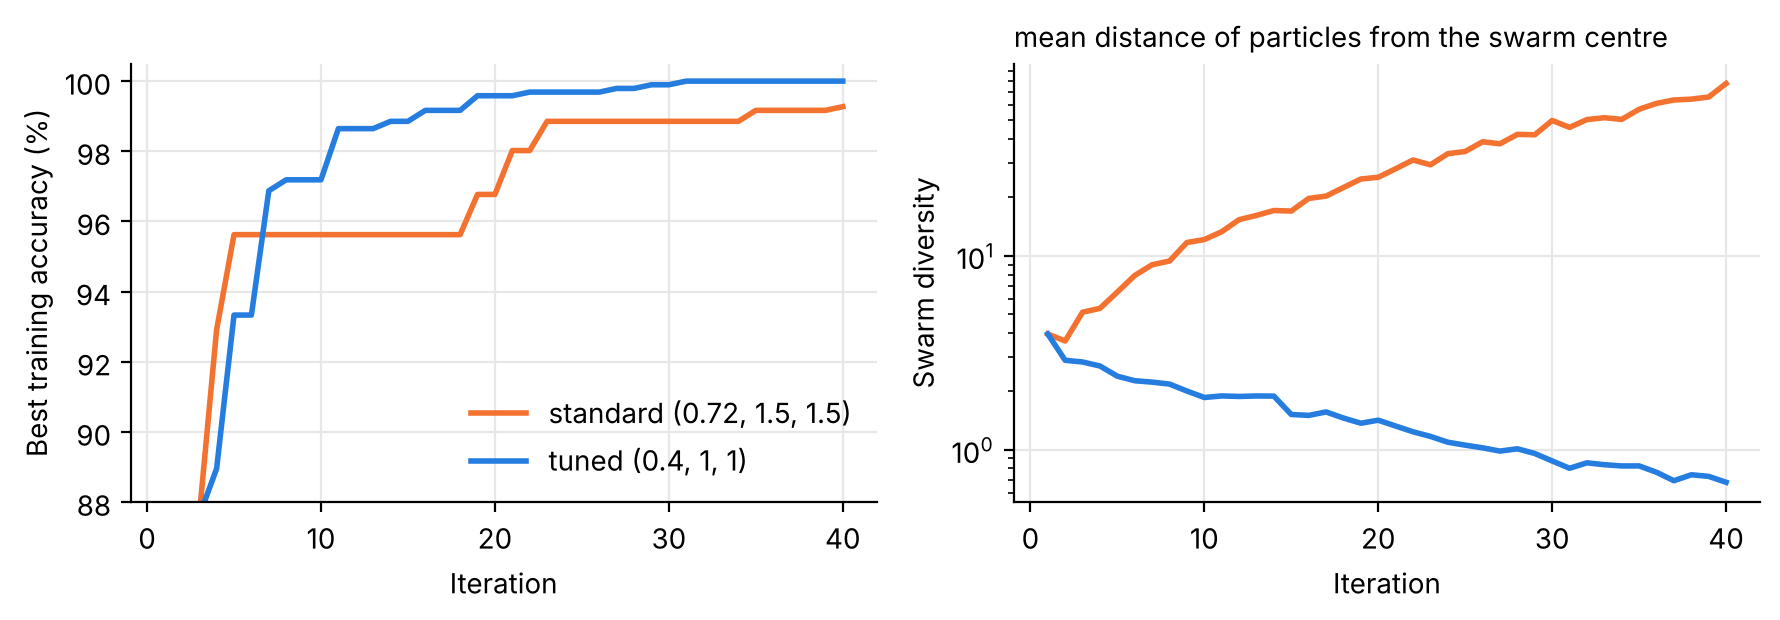

standard coefficients, test accuracy: 0.9830


In [7]:
standard = train(seed=0, alpha=0.72, beta=1.5, gamma=1.5)

fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3.2))
for run, colour, name in ((standard, ORANGE, "standard (0.72, 1.5, 1.5)"), (result, BLUE, "tuned (0.4, 1, 1)")):
    population = run["population"]
    iterations = range(1, len(population.fitness_history) + 1)
    left.plot(iterations, 100 * np.array(population.fitness_history), color=colour, label=name)
    right.plot(iterations, population.diversity_history, color=colour, label=name)
left.set_xlabel("Iteration"); left.set_ylabel("Best training accuracy (%)"); left.set_ylim(88, 100.5); left.legend(frameon=False)
right.set_xlabel("Iteration"); right.set_ylabel("Swarm diversity"); right.set_yscale("log")
right.set_title("mean distance of particles from the swarm centre", fontsize=10, loc="left")
plt.tight_layout(); plt.show()
print("standard coefficients, test accuracy: %.4f" % standard["accuracy"])

## 6. Small experiments

PSO is stochastic, so one run says little. The helper below repeats a setting with 10 seeds and
reports the mean and standard deviation of test accuracy. (The report uses 30 seeds per setting.)

In [8]:
def repeat(runs=10, **settings):
    scores = np.array([train(seed=seed, **settings)["accuracy"] for seed in range(runs)])
    return 100 * scores.mean(), 100 * scores.std(ddof=1)

STANDARD = dict(alpha=0.72, beta=1.5, gamma=1.5)
TUNED = dict(alpha=0.4, beta=1.0, gamma=1.0)

print("Velocity coefficients")
for name, coefficients in (("standard", STANDARD), ("tuned", TUNED)):
    print("  %-9s test accuracy %.2f +/- %.2f %%" % ((name,) + repeat(**coefficients)))

Velocity coefficients


  standard  test accuracy 97.57 +/- 0.67 %


  tuned     test accuracy 99.49 +/- 0.60 %


In [9]:
print("Architecture (tuned coefficients)")
for hidden in ((), (2,), (8,), (16,), (8, 8)):
    mean, std = repeat(hidden=hidden, activations=("tanh",) * len(hidden), **TUNED)
    print("  hidden layers %-8s test accuracy %.2f +/- %.2f %%" % (list(hidden), mean, std))

print("Activation, one hidden layer of 8 (tuned coefficients)")
for activation in ("logistic", "tanh", "relu"):
    print("  %-9s test accuracy %.2f +/- %.2f %%" % ((activation,) + repeat(activations=(activation,), **TUNED)))

Architecture (tuned coefficients)


  hidden layers []       test accuracy 98.30 +/- 0.71 %


  hidden layers [2]      test accuracy 98.67 +/- 1.04 %


  hidden layers [8]      test accuracy 99.49 +/- 0.60 %


  hidden layers [16]     test accuracy 99.68 +/- 0.40 %


  hidden layers [8, 8]   test accuracy 99.03 +/- 0.73 %
Activation, one hidden layer of 8 (tuned coefficients)


  logistic  test accuracy 98.76 +/- 0.45 %


  tanh      test accuracy 99.49 +/- 0.60 %


  relu      test accuracy 99.59 +/- 0.30 %


In [10]:
print("Spending 500 evaluations: swarm size x iterations (tuned coefficients)")
for swarm_size, iterations in ((5, 100), (10, 50), (25, 20), (50, 10), (100, 5)):
    mean, std = repeat(swarm_size=swarm_size, iterations=iterations, **TUNED)
    print("  %3d x %-3d  test accuracy %.2f +/- %.2f %%" % (swarm_size, iterations, mean, std))

Spending 500 evaluations: swarm size x iterations (tuned coefficients)


    5 x 100  test accuracy 92.11 +/- 5.39 %


   10 x 50   test accuracy 97.94 +/- 1.93 %


   25 x 20   test accuracy 98.50 +/- 0.81 %


   50 x 10   test accuracy 96.75 +/- 1.54 %


  100 x 5    test accuracy 93.98 +/- 2.06 %


In [11]:
print("Informant selection, 3 informants per particle")
for name, coefficients in (("standard", STANDARD), ("tuned", TUNED)):
    for strategy in ("random", "nearest", "ring"):
        mean, std = repeat(strategy=strategy, **coefficients)
        print("  %-9s %-8s test accuracy %.2f +/- %.2f %%" % (name, strategy, mean, std))

Informant selection, 3 informants per particle


  standard  random   test accuracy 97.57 +/- 0.67 %


  standard  nearest  test accuracy 98.81 +/- 0.78 %


  standard  ring     test accuracy 98.62 +/- 0.57 %


  tuned     random   test accuracy 99.49 +/- 0.60 %


  tuned     nearest  test accuracy 97.23 +/- 2.18 %


  tuned     ring     test accuracy 99.05 +/- 0.87 %


## 7. PSO choosing the activation function

With `ActivationSearchAdapter` the particle carries one extra number per hidden layer. Its range is
cut into equal bins, one per candidate activation (logistic, tanh, ReLU, leaky ReLU, ELU), and the
adapter sets the layer's activation from the bin before installing the weights. PSO itself is
unchanged: it just optimises a vector that is one element longer.

In [12]:
choices = []
for seed in range(10):
    run = train(seed=seed, search_activations=True, **TUNED)
    choices.append(run["network"].layers[0].activation.name)
    print("seed %d: chose %-10s test accuracy %.4f" % (seed, choices[-1], run["accuracy"]))
print("chosen:", {name: choices.count(name) for name in sorted(set(choices))})

seed 0: chose elu        test accuracy 0.9927


seed 1: chose elu        test accuracy 1.0000


seed 2: chose leaky_relu test accuracy 1.0000


seed 3: chose relu       test accuracy 0.9903


seed 4: chose elu        test accuracy 0.9927


seed 5: chose relu       test accuracy 1.0000


seed 6: chose tanh       test accuracy 0.9903


seed 7: chose tanh       test accuracy 0.9976


seed 8: chose relu       test accuracy 1.0000


seed 9: chose tanh       test accuracy 0.9879
chosen: {'elu': 3, 'leaky_relu': 1, 'relu': 3, 'tanh': 3}


## 8. Where the full results are

* `report/F21BC_Coursework_Report.pdf`: the coursework report.
* The companion repository `bio-inspired-coursework` contains the command-line scripts
  (`main.py`, `run_experiments.py`, `analyse_results.py`), the unit tests and `results/` with every
  table and figure of the study.